# Experiment 10 :: Low-Resource Neural Machine Translation (English - Assamese)

- Dataset: [WMT 2026 Indic MT](https://www2.statmt.org/wmt26/indic-mt-task.html), Category I, English-Assamese training data
- Models: NLLB-200 600M zero-shot, NLLB-200 1.3B zero-shot, NLLB-200 600M fine-tuned on 25,000 pairs
- Both directions, scored with chrF++, spBLEU and TER

Run on a Colab T4 GPU.

In [ ]:
%pip install -q transformers sentencepiece sacrebleu gdown pandas matplotlib

In [ ]:
import gc
import json
import math
import os
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch

assert torch.cuda.is_available()
print(torch.cuda.get_device_name(0))
os.makedirs('outputs', exist_ok=True)

Tesla T4


## 10.1 Data collection

In [ ]:
import gdown

csv_path = 'en-as-2026.csv'
if not os.path.exists(csv_path):
    gdown.download(id='1W4AE95P7zWWyZ6crkdK2i7pR9_XPKbLZ', output=csv_path, quiet=True)

raw = pd.read_csv(csv_path, encoding='utf-8-sig', keep_default_na=False)
print(raw.shape)
raw.head()

(54000, 2)


,en,as
0,Similarly there is a great need for value addi...,ঠিক একেধৰণে মাটিকঁঠালৰ মূল্য সংযোজনৰ যথেষ্ট আৱ...
1,Lemon tanga also has a good market for sorbet ...,নেমুটেঙাৰ চৰবত আচাৰ আদিৰো ভাল বজাৰ আছে ।
2,These crops are very much available in Assam b...,এই শস্যকেইবিধ অসমত যথেষ্ট হয় কিন্তু মূল্য সংযো...
3,A lot of money goes out of the state exchequer...,অসমলৈ বহু পৰিমাণৰ বীজ আমদানি কৰাৰ বাবে ৰাজ্যখন...
4,But many youth of the state can be established...,কিন্তু ধান সৰিয়হ মাটিমাহ নেমু কল বহুতো ফল ফুলৰ...


## 10.2 Preprocessing

1. Unicode NFC, invisible characters removed, whitespace collapsed
2. Space before punctuation removed (`soil .` becomes `soil.`)
3. Duplicates removed on both the English and the Assamese side before splitting, so no test sentence appears in training
4. Pairs dropped when they are too short or long, when the two lengths differ by more than 3x, or when the script is wrong

In [ ]:
import random
import re
import unicodedata

space_before = re.compile(r'\s+([.,!?;:।%)\]])')
space_after = re.compile(r'([(\[])\s+')
invisible = re.compile(r'[​‎‏⁠﻿­]')


def clean(text):
    text = unicodedata.normalize('NFC', text)
    text = invisible.sub('', text)
    text = ' '.join(text.split())
    return space_after.sub(r'\1', space_before.sub(r'\1', text))


def assamese_ratio(text):
    letters = [c for c in text if unicodedata.category(c)[0] in 'LM']
    return sum('ঀ' <= c <= '৿' for c in letters) / max(len(letters), 1)


def keep(en, as_):
    ne, na = len(en.split()), len(as_.split())
    return 2 <= ne <= 80 and 2 <= na <= 80 and 1 / 3 <= ne / na <= 3 and assamese_ratio(as_) >= 0.8 and assamese_ratio(en) < 0.1


assert clean('soil .') == 'soil.'
assert clean('আছে ।') == 'আছে।'
assert not keep('a good day', 'a good day')

In [ ]:
pairs = [(clean(e), clean(a)) for e, a in zip(raw['en'], raw['as'])]

seen_en, seen_as, unique = set(), set(), []
for en, as_ in pairs:
    if en.lower() in seen_en or as_ in seen_as:
        continue
    seen_en.add(en.lower())
    seen_as.add(as_)
    unique.append((en, as_))

kept = [p for p in unique if keep(*p)]
random.Random(42).shuffle(kept)
test, dev, pool = kept[:2000], kept[2000:3000], kept[3000:]
train = pool[:25000]

assert not {e.lower() for e, _ in test + dev} & {e.lower() for e, _ in train}
assert not {a for _, a in test + dev} & {a for _, a in train}

stats = {'raw': len(pairs), 'after_dedup': len(unique), 'after_filter': len(kept),
         'train_available': len(pool), 'train_used': len(train), 'dev': len(dev), 'test': len(test)}
print(stats)
print('Mean words:', sum(len(e.split()) for e, _ in kept) / len(kept), sum(len(a.split()) for _, a in kept) / len(kept))
print('Vocabulary:', len({w.lower() for e, _ in kept for w in e.split()}), len({w for _, a in kept for w in a.split()}))

{'raw': 54000, 'after_dedup': 47458, 'after_filter': 47005, 'train_available': 44005, 'train_used': 25000, 'dev': 1000, 'test': 2000}
Mean words: 16.607041804063396 14.379512817785342
Vocabulary: 52593 76541


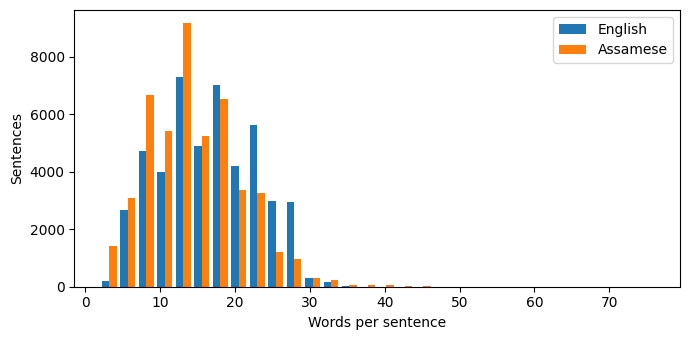

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist([[len(e.split()) for e, _ in kept], [len(a.split()) for _, a in kept]], bins=30, label=['English', 'Assamese'])
ax.set_xlabel('Words per sentence')
ax.set_ylabel('Sentences')
ax.legend()
plt.tight_layout()
plt.show()

## 10.3 Subword tokenization

In [ ]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

small_name = 'facebook/nllb-200-distilled-600M'
large_name = 'facebook/nllb-200-distilled-1.3B'
codes = {'en': 'eng_Latn', 'as': 'asm_Beng'}
tokenizer = AutoTokenizer.from_pretrained(small_name)

tokenizer.src_lang = codes['as']
print(test[0][0])
print(tokenizer.tokenize(test[0][0]))
print(test[0][1])
print(tokenizer.tokenize(test[0][1]))

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/3.55k [00:00<?, ?B/s]

(Leviticus 25: 43) Thus, when Joseph saw ample proof of his brothers’ change of heart, he mercifully forgave them.
['▁(', 'Levit', 'icus', '▁25:', '▁43)', '▁Thus', ',', '▁when', '▁Joseph', '▁saw', '▁am', 'ple', '▁proof', '▁of', '▁his', '▁brothers', '<unk>', '▁change', '▁of', '▁heart', ',', '▁he', '▁merci', 'fully', '▁for', 'gave', '▁them', '.']
(লেবীয়া পুস্তক ২৫: ৪৩) সেয়েহে যেতিয়া যোচেফে তেওঁৰ ভাইসকলে নিজ নিজ মন সলনি কৰাৰ অতিৰিক্ত প্ৰমাণ পালে, তেতিয়া তেওঁ তেওঁলোকলৈ দয়ালুপূৰ্ণ আচৰণ কৰিলে আৰু তেওঁলোকে কৰা ভুলৰ বাবে ক্ষমা কৰিলে।
['▁(', 'লে', 'ব', 'ীয়া', '▁পু', 'স্ত', 'ক', '▁২৫', ':', '▁৪', '৩', ')', '▁সেয়ে', 'হে', '▁যেতিয়া', '▁য', 'ো', 'চে', 'ফে', '▁তেওঁৰ', '▁ভাই', 'সকলে', '▁নিজ', '▁নিজ', '▁মন', '▁সলনি', '▁কৰাৰ', '▁অতি', 'ৰিক', '্ত', '▁প্ৰ', 'মাণ', '▁পালে', ',', '▁তেতিয়া', '▁তেওঁ', '▁তেওঁলোক', 'লৈ', '▁দ', 'য়াল', 'ুপ', 'ূৰ্ণ', '▁আচ', 'ৰণ', '▁কৰিলে', '▁আৰু', '▁তেওঁলোকে', '▁কৰা', '▁ভুল', 'ৰ', '▁বাবে', '▁ক্ষমা', '▁কৰিলে', '।']


## 10.4 Training and evaluation functions

In [ ]:
from sacrebleu.metrics import BLEU, CHRF, TER

sides = {'en': 0, 'as': 1}


def free():
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def translate(model, sources, src, tgt, batch_size=24):
    model.eval()
    model.generation_config.max_length = None
    tokenizer.src_lang = codes[src]
    order = sorted(range(len(sources)), key=lambda i: -len(sources[i]))
    result = [None] * len(sources)
    for start in range(0, len(order), batch_size):
        index = order[start:start + batch_size]
        inputs = tokenizer([sources[i] for i in index], return_tensors='pt', padding=True, truncation=True, max_length=128).to('cuda')
        ids = model.generate(**inputs, forced_bos_token_id=tokenizer.convert_tokens_to_ids(codes[tgt]), num_beams=4, max_new_tokens=160)
        for i, text in zip(index, tokenizer.batch_decode(ids, skip_special_tokens=True)):
            result[i] = clean(text)
    return result


def score(hypotheses, references):
    return {'chrF++': CHRF(word_order=2).corpus_score(hypotheses, [references]).score,
            'spBLEU': BLEU(tokenize='flores200').corpus_score(hypotheses, [references]).score,
            'TER': TER().corpus_score(hypotheses, [references]).score}


def make_batch(batch, src, tgt):
    tokenizer.src_lang, tokenizer.tgt_lang = codes[src], codes[tgt]
    encoded = tokenizer([p[sides[src]] for p in batch], text_target=[p[sides[tgt]] for p in batch],
                        return_tensors='pt', padding=True, truncation=True, max_length=128)
    encoded['labels'][encoded['labels'] == tokenizer.pad_token_id] = -100
    return encoded.to('cuda')


@torch.no_grad()
def dev_loss(model, src, tgt):
    model.eval()
    total, tokens = 0.0, 0
    for start in range(0, len(dev), 8):
        batch = make_batch(dev[start:start + 8], src, tgt)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = model(**batch).loss
        n = (batch['labels'] != -100).sum().item()
        total += loss.item() * n
        tokens += n
    return total / tokens


def fine_tune(src, tgt, epochs=2, batch_size=16, lr=1e-4, warmup=200):
    torch.manual_seed(42)
    model = AutoModelForSeq2SeqLM.from_pretrained(small_name, torch_dtype=torch.float32).to('cuda')
    for p in model.get_input_embeddings().parameters():
        p.requires_grad_(False)
    params = [p for p in model.parameters() if p.requires_grad]
    print('Trainable parameters:', sum(p.numel() for p in params), 'of', sum(p.numel() for p in model.parameters()))
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(len(train) / batch_size)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min((s + 1) / warmup, max(0.0, (steps - s) / max(1, steps - warmup))))
    scaler = torch.amp.GradScaler('cuda')
    rng = random.Random(42)
    history = [{'epoch': 0, 'train_loss': None, 'dev_loss': dev_loss(model, src, tgt)}]
    print(history[-1])
    start_time = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        data = train[:]
        rng.shuffle(data)
        chunks = [sorted(data[i:i + 800], key=lambda p: len(p[0])) for i in range(0, len(data), 800)]
        batches = [c[i:i + batch_size] for c in chunks for i in range(0, len(c), batch_size)]
        rng.shuffle(batches)
        running = 0.0
        for step, b in enumerate(batches, 1):
            for i in range(0, len(b), 8):
                part = b[i:i + 8]
                with torch.autocast('cuda', dtype=torch.float16):
                    loss = model(**make_batch(part, src, tgt)).loss * len(part) / len(b)
                scaler.scale(loss).backward()
                running += loss.item()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            if step % 300 == 0:
                print(f'epoch {epoch} step {step}/{len(batches)} loss {running / step:.4f} {time.time() - start_time:.0f}s')
        history.append({'epoch': epoch, 'train_loss': running / len(batches), 'dev_loss': dev_loss(model, src, tgt)})
        print(history[-1])
    return model, history, (time.time() - start_time) / 60


results, hypotheses, histories = {}, {}, {}


def evaluate(name, model, src, tgt, train_minutes=0.0):
    key = f'{src}-{tgt}'
    start = time.time()
    output = translate(model, [p[sides[src]] for p in test], src, tgt)
    hypotheses.setdefault(key, {})[name] = output
    results.setdefault(key, {})[name] = {**score(output, [p[sides[tgt]] for p in test]),
                                         'train_min': train_minutes, 'decode_min': (time.time() - start) / 60}
    print(key, name, results[key][name])
    json.dump(results, open('outputs/results.json', 'w'), indent=2)
    json.dump(hypotheses, open('outputs/hypotheses.json', 'w'), ensure_ascii=False)


directions = [('en', 'as'), ('as', 'en')]

## 10.5 NLLB-200 600M, zero-shot

In [ ]:
model = AutoModelForSeq2SeqLM.from_pretrained(small_name, torch_dtype=torch.float16).to('cuda')
for src, tgt in directions:
    evaluate('NLLB-600M zero-shot', model, src, tgt)
del model
free()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.46GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

en-as NLLB-600M zero-shot {'chrF++': 33.11112360222298, 'spBLEU': 18.45656544290125, 'TER': 86.48967961637362, 'train_min': 0.0, 'decode_min': 2.758806816736857}
as-en NLLB-600M zero-shot {'chrF++': 43.700068360061415, 'spBLEU': 23.195335694676135, 'TER': 74.53588921811695, 'train_min': 0.0, 'decode_min': 2.0020038723945617}


## 10.6 NLLB-200 1.3B, zero-shot

In [10]:
model = AutoModelForSeq2SeqLM.from_pretrained(large_name, torch_dtype=torch.float16).to('cuda')
for src, tgt in directions:
    evaluate('NLLB-1.3B zero-shot', model, src, tgt)
del model
free()

config.json:   0%|          | 0.00/808 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 5.48GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.48GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1016 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

en-as NLLB-1.3B zero-shot {'chrF++': 35.17555741537528, 'spBLEU': 21.325330396297794, 'TER': 81.81597053304608, 'train_min': 0.0, 'decode_min': 3.1327295541763305}
as-en NLLB-1.3B zero-shot {'chrF++': 48.429302296740985, 'spBLEU': 29.488095800715307, 'TER': 68.18044385317772, 'train_min': 0.0, 'decode_min': 3.031863562266032}


## 10.7 NLLB-200 600M, fine-tuned

Embeddings are frozen (256k tokens, shared with the output layer). AdamW, learning rate 1e-4 with warmup and linear decay, 2 epochs, batch size 16 (two micro-batches of 8 to fit in T4 memory), mixed precision.

In [11]:
for src, tgt in directions:
    model, history, minutes = fine_tune(src, tgt)
    histories[f'{src}-{tgt}'] = history
    evaluate('NLLB-600M fine-tuned', model.half(), src, tgt, minutes)
    del model
    free()
json.dump(histories, open('outputs/histories.json', 'w'), indent=2)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Trainable parameters: 352718848 of 615073792
{'epoch': 0, 'train_loss': None, 'dev_loss': 2.440291073927668}
epoch 1 step 300/1563 loss 2.0717 133s
epoch 1 step 600/1563 loss 1.9923 264s
epoch 1 step 900/1563 loss 1.9487 398s
epoch 1 step 1200/1563 loss 1.9161 532s
epoch 1 step 1500/1563 loss 1.8873 665s
{'epoch': 1, 'train_loss': 1.8831122848786228, 'dev_loss': 1.7193216783454253}
epoch 2 step 300/1563 loss 1.5623 834s
epoch 2 step 600/1563 loss 1.5529 967s
epoch 2 step 900/1563 loss 1.5514 1100s
epoch 2 step 1200/1563 loss 1.5405 1232s
epoch 2 step 1500/1563 loss 1.5345 1364s
{'epoch': 2, 'train_loss': 1.5335675364911976, 'dev_loss': 1.6842065671998518}
en-as NLLB-600M fine-tuned {'chrF++': 39.70840414891459, 'spBLEU': 25.860481632558326, 'TER': 77.84418653137813, 'train_min': 23.32440405289332, 'decode_min': 2.480381409327189}


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Trainable parameters: 352718848 of 615073792
{'epoch': 0, 'train_loss': None, 'dev_loss': 1.9974142191057689}
epoch 1 step 300/1563 loss 1.8249 124s
epoch 1 step 600/1563 loss 1.7701 248s
epoch 1 step 900/1563 loss 1.7387 373s
epoch 1 step 1200/1563 loss 1.7099 499s
epoch 1 step 1500/1563 loss 1.6856 625s
{'epoch': 1, 'train_loss': 1.68310817578475, 'dev_loss': 1.5689022507805985}
epoch 2 step 300/1563 loss 1.3440 785s
epoch 2 step 600/1563 loss 1.3446 911s
epoch 2 step 900/1563 loss 1.3414 1037s
epoch 2 step 1200/1563 loss 1.3315 1163s
epoch 2 step 1500/1563 loss 1.3242 1288s
{'epoch': 2, 'train_loss': 1.3232577120407376, 'dev_loss': 1.549669236557904}
as-en NLLB-600M fine-tuned {'chrF++': 49.15635051818827, 'spBLEU': 30.52081036630193, 'TER': 64.29824030960876, 'train_min': 22.030448242028555, 'decode_min': 1.5765588243802389}


## 10.8 Model comparison

In [ ]:
for key in results:
    print(key)
    display(pd.DataFrame(results[key]).T.round(2))

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for row, key in zip(axes, results):
    table = pd.DataFrame(results[key]).T
    for ax, metric in zip(row, ['chrF++', 'spBLEU', 'TER']):
        bars = ax.bar(['600M zs', '1.3B zs', '600M ft'], table[metric], color=['#9aa5b1', '#627d98', '#d64545'])
        ax.bar_label(bars, fmt='%.1f')
        ax.set_title(f'{key} {metric}')
plt.tight_layout()
plt.savefig('outputs/comparison.png', dpi=160)
plt.show()

## 10.9 Bootstrap test

95% interval of the chrF++ gain of the fine-tuned model over each zero-shot model, from 500 resamples of the test set.

In [13]:
import numpy as np

chrf = CHRF(word_order=2)
bootstrap = {}


def sentence_stats(hyps, refs):
    return np.array([chrf._extract_corpus_statistics([h], [[r]])[0] for h, r in zip(hyps, refs)])


for src, tgt in directions:
    key = f'{src}-{tgt}'
    refs = [p[sides[tgt]] for p in test]
    stat = {n: sentence_stats(h, refs) for n, h in hypotheses[key].items()}
    rng = np.random.default_rng(42)
    for base in ['NLLB-600M zero-shot', 'NLLB-1.3B zero-shot']:
        gains = []
        for _ in range(500):
            i = rng.integers(0, len(refs), len(refs))
            f = chrf._compute_score_from_stats(stat['NLLB-600M fine-tuned'][i].sum(0).tolist()).score
            b = chrf._compute_score_from_stats(stat[base][i].sum(0).tolist()).score
            gains.append(f - b)
        bootstrap[f'{key} vs {base}'] = np.percentile(gains, [2.5, 50, 97.5]).round(2).tolist()
print(bootstrap)

{'en-as vs NLLB-600M zero-shot': [5.97, 6.58, 7.13], 'en-as vs NLLB-1.3B zero-shot': [3.93, 4.55, 5.21], 'as-en vs NLLB-600M zero-shot': [4.97, 5.46, 5.94], 'as-en vs NLLB-1.3B zero-shot': [0.18, 0.72, 1.31]}


## 10.10 Sample translations

In [14]:
samples = {}
for src, tgt in directions:
    key = f'{src}-{tgt}'
    for i in [0, 1, 2, 3, 4, 5]:
        print(key, i)
        print('SRC:', test[i][sides[src]])
        print('REF:', test[i][sides[tgt]])
        for name, output in hypotheses[key].items():
            print(f'{name}:', output[i])
        print()

json.dump({'stats': stats, 'results': results, 'histories': histories, 'bootstrap': bootstrap}, open('outputs/summary.json', 'w'), indent=2)
print(json.dumps({'stats': stats, 'results': results, 'histories': histories, 'bootstrap': bootstrap}))

en-as 0
SRC: (Leviticus 25: 43) Thus, when Joseph saw ample proof of his brothers’ change of heart, he mercifully forgave them.
REF: (লেবীয়া পুস্তক ২৫: ৪৩) সেয়েহে যেতিয়া যোচেফে তেওঁৰ ভাইসকলে নিজ নিজ মন সলনি কৰাৰ অতিৰিক্ত প্ৰমাণ পালে, তেতিয়া তেওঁ তেওঁলোকলৈ দয়ালুপূৰ্ণ আচৰণ কৰিলে আৰু তেওঁলোকে কৰা ভুলৰ বাবে ক্ষমা কৰিলে।
NLLB-600M zero-shot: (লিবিতীয়া ২৫ঃ৪৩) এইদৰে যোচেফে যেতিয়া তেওঁৰ ভাই-ভনীসকলৰ মন পৰিৱৰ্তনৰ প্ৰমাণ দেখিলে, তেতিয়া তেওঁ তেওঁলোকক ক্ষমা কৰিলে।
NLLB-1.3B zero-shot: (লেবীয়া ২৫:৪৩) সেয়ে, যেতিয়া যোচেফে তেওঁৰ ভাতৃসকলৰ মনৰ পৰিৱৰ্তনৰ যথেষ্ট প্ৰমাণ দেখিলে, তেতিয়া তেওঁ তেওঁলোকক ক্ষমা কৰিলে।
NLLB-600M fine-tuned: (লেবীয়া পুস্তক ২৫: ৪৩) এইদৰে যোচেফে নিজৰ ভায়েকবিলাকৰ মন পালটাৰ প্ৰমাণ দেখি অনুগ্ৰহ কৰি তেওঁলোকক ক্ষমা কৰিলে।

en-as 1
SRC: Their father Jacob has sent them to Egypt because they were running out of food back home in Caʹnaan.
REF: কনান দেশত আকাল হোৱাৰ বাবে যাকোবে তেওঁলোকক মিচৰৰপৰা আহাৰ কিনি আনিবলৈ পঠাইছে।
NLLB-600M zero-shot: যিহেতু তেওঁলোকৰ পিতৃ যাকোবে মিচৰ দেশলৈ প